# California Housing Prices — Exploratory Data Analysis

This notebook performs an exploratory data analysis (EDA) of the California Housing Prices dataset.

The goal of this analysis is to understand the structure, quality, distribution, and relationships within the dataset before building a machine learning model.

## Dataset

The dataset was obtained from Kaggle:

[California Housing Prices — Kaggle](https://www.kaggle.com/datasets/camnugent/california-housing-prices)

This dataset contains information about housing districts in California based on data from the 1990 U.S. Census.

## Objectives

- Understand the structure of the dataset
- Inspect data types and basic statistics
- Identify missing values and duplicate records
- Analyze feature distributions (numerical and categorical)
- Detect potential outliers
- Explore correlations between features and the target variable
- Investigate relationships between important features and house prices, including geographic patterns
- Identify data quality issues (e.g. capped values) that affect modeling
- Identify useful insights for the modeling stage

## 1. Import Libraries

We import the libraries required for data manipulation, numerical analysis, and visualization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

%matplotlib inline
sns.set_style("whitegrid")

## 2. Load Dataset

We load the dataset into a pandas DataFrame for further analysis.

In [2]:
df = pd.read_csv("../data/housing.csv")

## 3. Initial Data Inspection

Before performing detailed analysis, we inspect the basic structure and contents of the dataset.

In [3]:
print("Shape:", df.shape)

df.head()

Shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


## 4. Missing Values

Missing values can affect data analysis and machine learning models.

We identify the number and percentage of missing values in each feature.

In [5]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [6]:
missing_percentage = df.isnull().mean() * 100
missing_percentage.sort_values(ascending=False)

total_bedrooms        1.002907
longitude             0.000000
latitude              0.000000
housing_median_age    0.000000
total_rooms           0.000000
population            0.000000
households            0.000000
median_income         0.000000
median_house_value    0.000000
ocean_proximity       0.000000
dtype: float64

## 5. Duplicate Records

We check whether the dataset contains duplicate rows.

In [7]:
df.duplicated().sum()

np.int64(0)

## 6. Descriptive Statistics

Descriptive statistics provide an overview of the numerical features, including their count, mean, standard deviation, minimum, maximum, and quartiles.

`ocean_proximity` is the only categorical column in the dataset, so we describe it separately.

In [8]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [9]:
# Categorical feature summary
df.describe(include="object")

,ocean_proximity
count,20640
unique,5
top,<1H OCEAN
freq,9136


In [10]:
df["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

## 7. Numerical Feature Distributions

We visualize the distributions of numerical features to understand their range, spread, skewness, and potential unusual values.

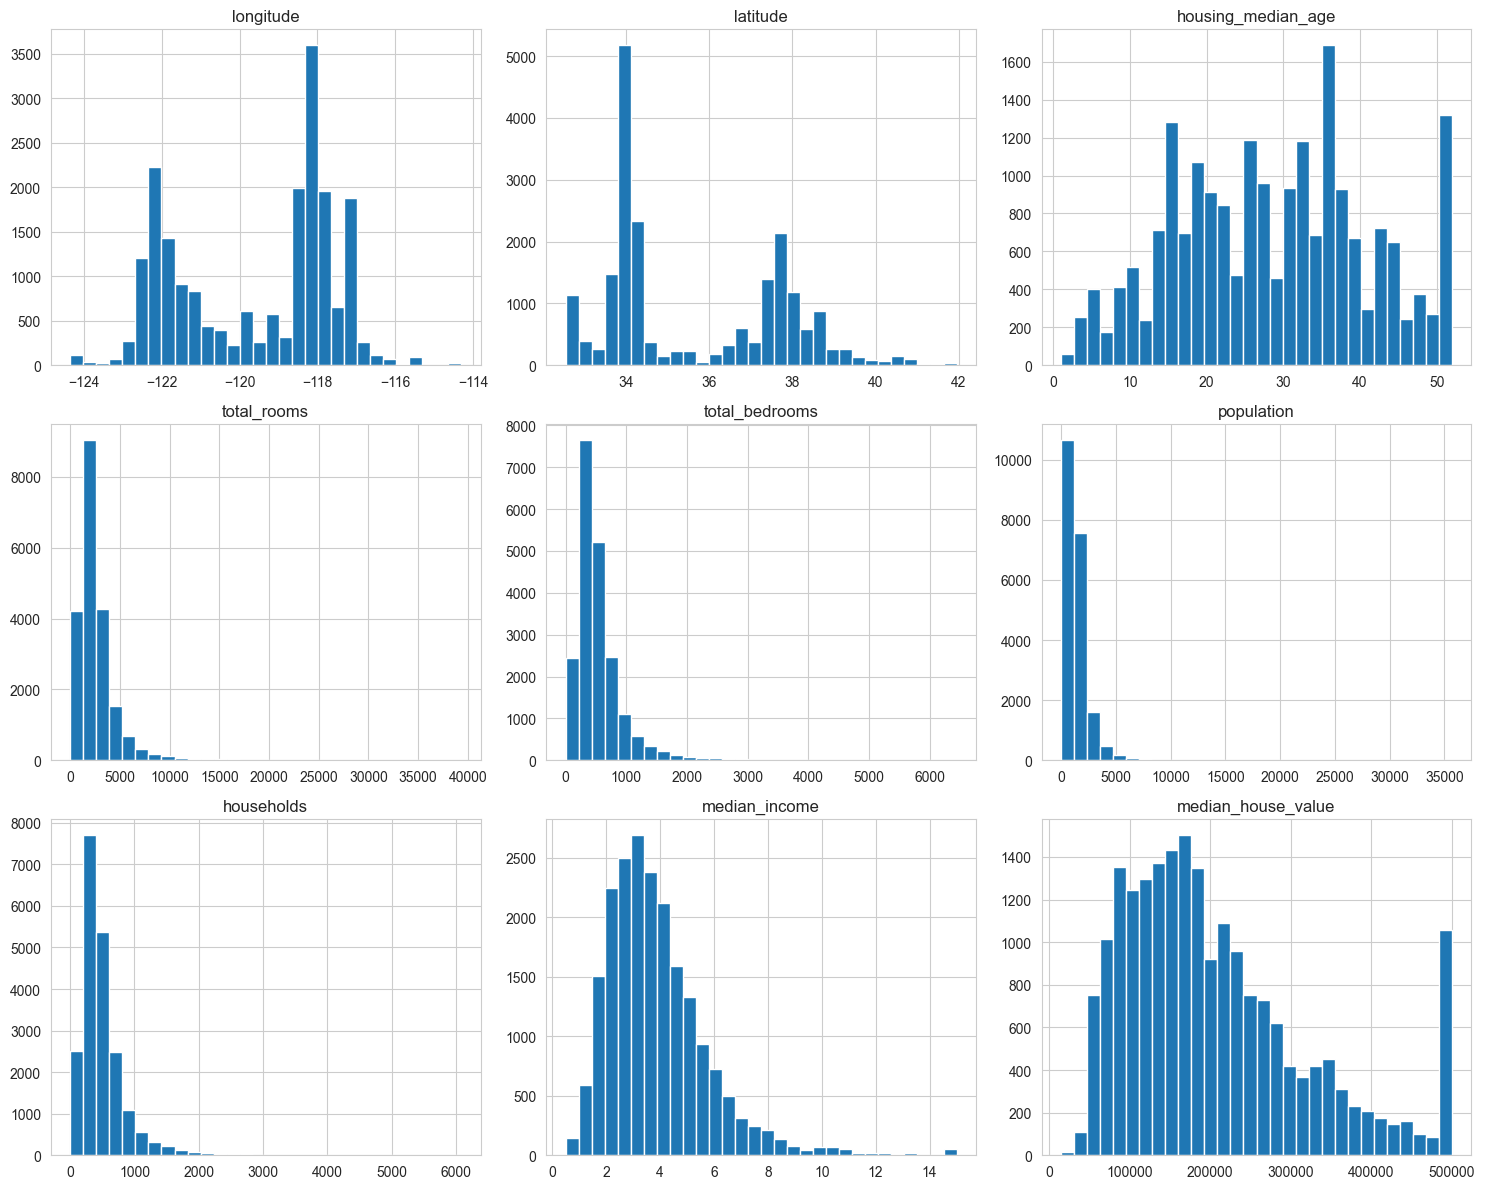

In [11]:
numerical_features = df.select_dtypes(include=np.number).columns

df[numerical_features].hist(
    figsize=(15, 12),
    bins=30
)

plt.tight_layout()

## 8. Categorical Feature Distribution

We look at the distribution of `ocean_proximity`, since it was excluded from the numerical analysis above but can still be informative for the target variable.

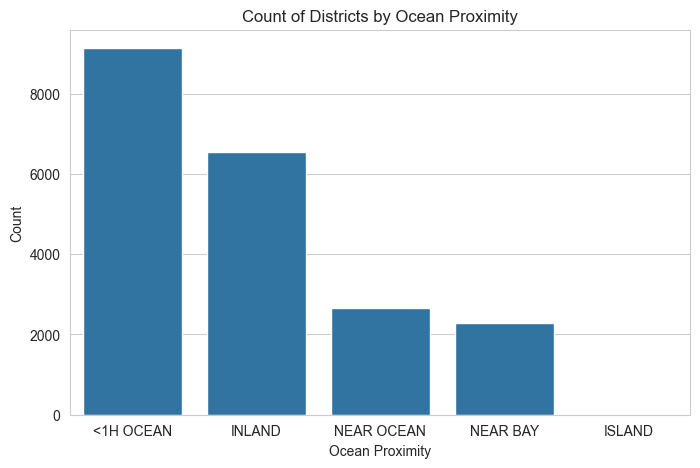

In [12]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,x="ocean_proximity",order=df["ocean_proximity"].value_counts().index)

plt.title("Count of Districts by Ocean Proximity")
plt.xlabel("Ocean Proximity")
plt.ylabel("Count");

## 9. Target Variable Distribution

The target variable for this project is `median_house_value`.

We examine its distribution to understand the range and overall shape of house prices.

**Note:** this dataset is known to have `median_house_value` capped at $500,001 — districts with a "true" value above that threshold were recorded at the cap. We check for this below, since it affects how the target should be handled during modeling.

Text(0, 0.5, 'Frequency')

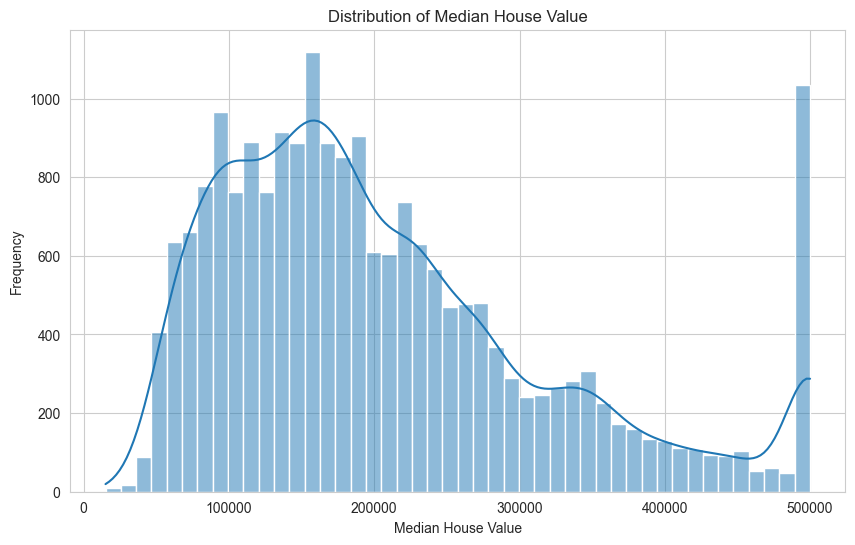

In [13]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="median_house_value",
    kde=True
)

plt.title("Distribution of Median House Value")
plt.xlabel("Median House Value")
plt.ylabel("Frequency")

In [14]:
capped_value = df["median_house_value"].max()
capped_count = (df["median_house_value"] == capped_value).sum()
capped_pct = capped_count / len(df) * 100

print(f"Max median_house_value: {capped_value}")
print(f"Districts at the cap: {capped_count} ({capped_pct:.2f}% of the dataset)")

Max median_house_value: 500001.0
Districts at the cap: 965 (4.68% of the dataset)


If a non-trivial share of districts sit exactly at the maximum value, this is a **capping artifact**, not a natural outlier. Options to consider for modeling: drop capped rows, treat the task as censored regression, or clearly note the ceiling effect when evaluating predictions near the cap.

The same capping pattern is worth checking for `housing_median_age` (commonly capped at 52).

In [15]:
capped_age = df["housing_median_age"].max()
capped_age_count = (df["housing_median_age"] == capped_age).sum()

print(f"Max housing_median_age: {capped_age}")
print(f"Districts at the cap: {capped_age_count} ({capped_age_count / len(df) * 100:.2f}% of the dataset)")

Max housing_median_age: 52.0
Districts at the cap: 1273 (6.17% of the dataset)


## 10. Outlier Detection

Boxplots are used to identify potential outliers in numerical features.

An outlier is not necessarily an incorrect observation. Potential outliers should be investigated before deciding whether they should be removed or transformed.

**Note:** the numerical features here have very different scales (e.g. `population` can be in the tens of thousands while `housing_median_age` tops out around 50), so plotting them on one shared axis makes most boxes unreadable. We plot each feature in its own subplot instead.

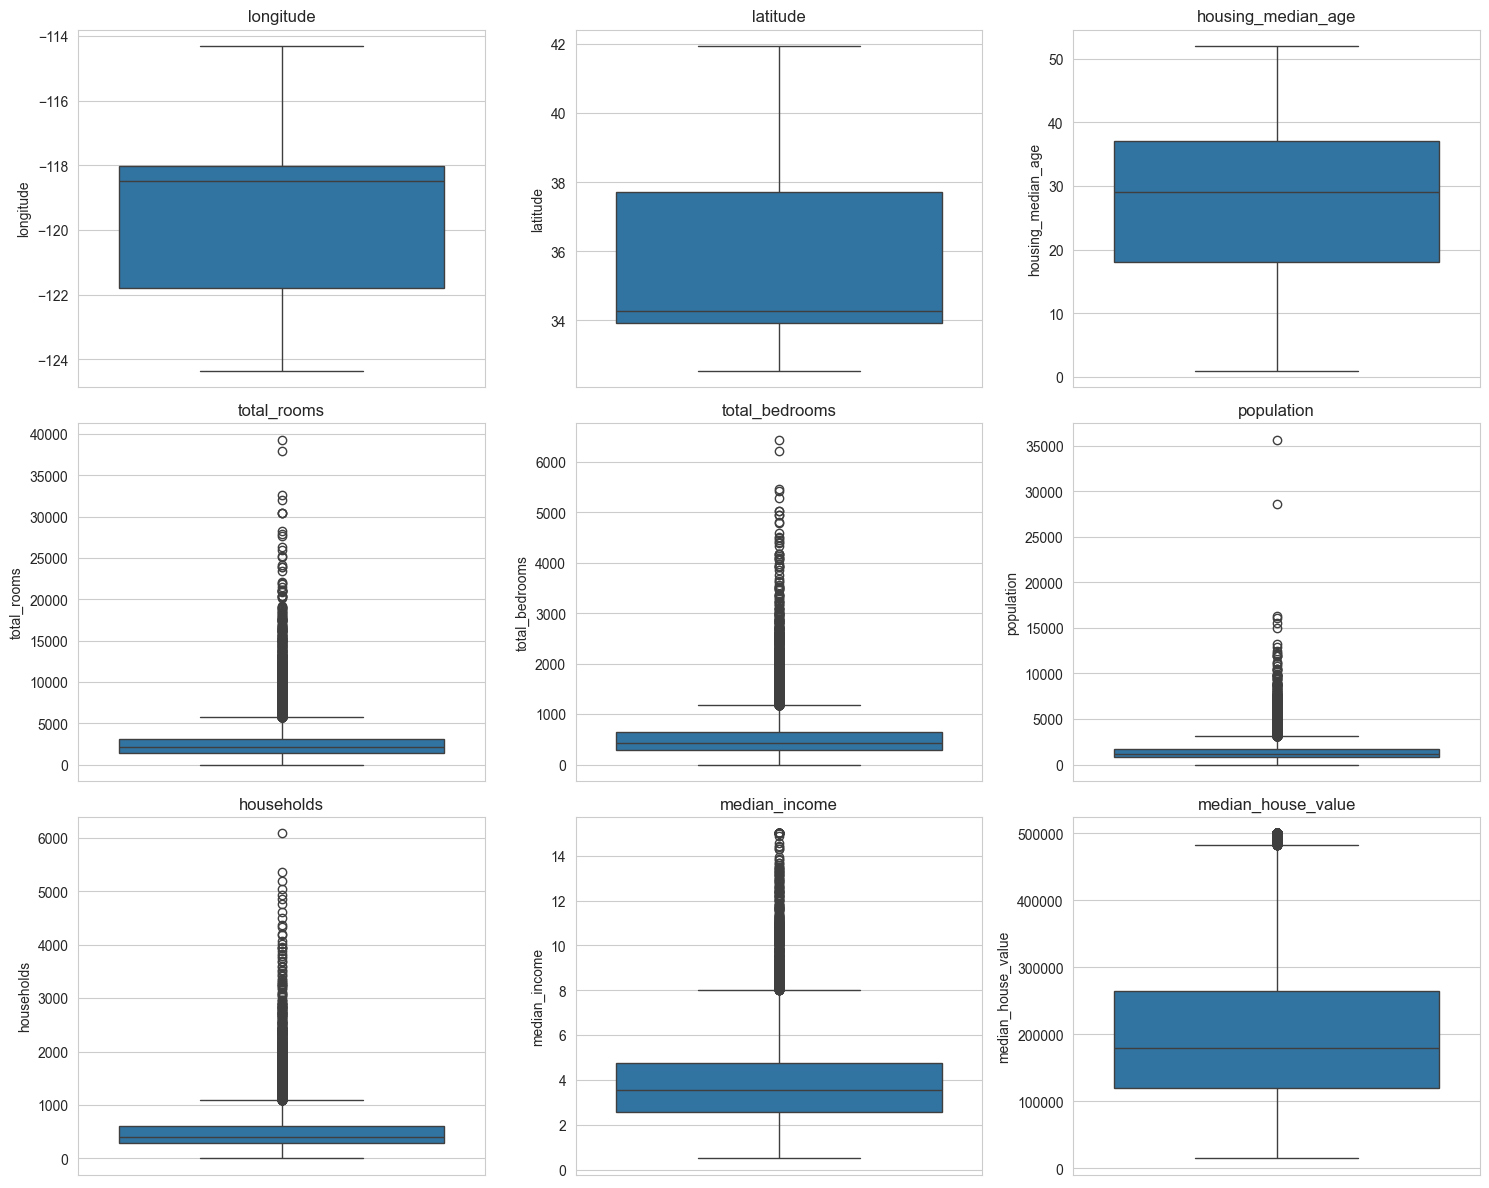

In [16]:
n_cols = 3
n_rows = int(np.ceil(len(numerical_features) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(numerical_features):
    sns.boxplot(data=df, y=col, ax=axes[i])
    axes[i].set_title(col)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()

## 11. Geographic Distribution

California housing prices are strongly tied to location. Plotting `latitude` and `longitude`, colored by `median_house_value`, gives geographic context to every other finding in this notebook (coastal areas, the Bay Area, and greater LA are expected to stand out).

Text(0, 0.5, 'Latitude')

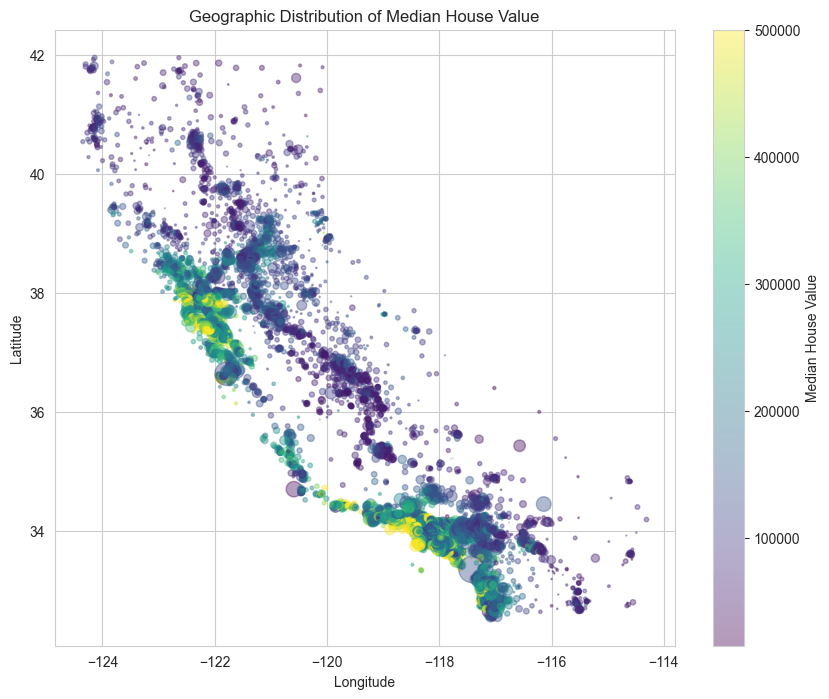

In [21]:
plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    df["longitude"],
    df["latitude"],
    c=df["median_house_value"],
    cmap="viridis",
    s=df["population"] / 100,
    alpha=0.4
)

plt.colorbar(scatter, label="Median House Value")
plt.title("Geographic Distribution of Median House Value")
plt.xlabel("Longitude")
plt.ylabel("Latitude")


In [ ]:
fig = px.scatter(
    df,
    x="longitude",
    y="latitude",
    color="median_house_value",
    size="population_scaled",
    opacity=0.4,
    color_continuous_scale="Viridis",
    title="Geographic Distribution of Median House Value",
    labels={
        "longitude": "Longitude",
        "latitude": "Latitude",
        "median_house_value": "Median House Value",
        "population": "Population"
    }
)

fig.show()

## 12. Correlation Analysis

We examine the linear correlation between numerical features.

Correlation can help identify relationships between features and the target variable.

Correlation does not imply causation.

In [20]:
correlation_matrix = df[numerical_features].corr()

correlation_matrix

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.924664,-0.108197,0.044568,0.069608,0.099773,0.055310,-0.015176,-0.045967
latitude,-0.924664,1.000000,0.011173,-0.036100,-0.066983,-0.108785,-0.071035,-0.079809,-0.144160
housing_median_age,-0.108197,0.011173,1.000000,-0.361262,-0.320451,-0.296244,-0.302916,-0.119034,0.105623
total_rooms,0.044568,-0.036100,-0.361262,1.000000,0.930380,0.857126,0.918484,0.198050,0.134153
total_bedrooms,0.069608,-0.066983,-0.320451,0.930380,1.000000,0.877747,0.979728,-0.007723,0.049686
population,0.099773,-0.108785,-0.296244,0.857126,0.877747,1.000000,0.907222,0.004834,-0.024650
households,0.055310,-0.071035,-0.302916,0.918484,0.979728,0.907222,1.000000,0.013033,0.065843
median_income,-0.015176,-0.079809,-0.119034,0.198050,-0.007723,0.004834,0.013033,1.000000,0.688075
median_house_value,-0.045967,-0.144160,0.105623,0.134153,0.049686,-0.024650,0.065843,0.688075,1.000000


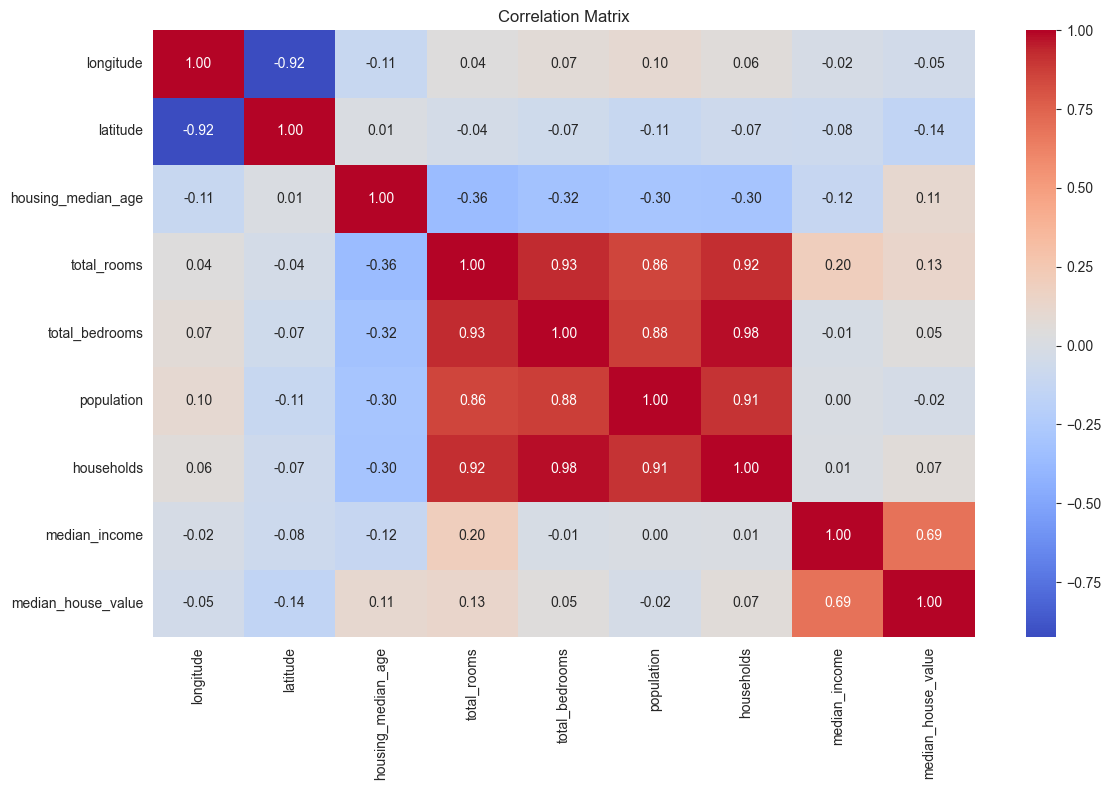

In [21]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix")

plt.tight_layout()
plt.show()

### Correlation with Target

We examine the correlation of each numerical feature with `median_house_value` to identify features that have stronger linear relationships with the target.

In [22]:
target_correlation = (
    correlation_matrix["median_house_value"]
    .sort_values(ascending=False)
)

target_correlation

median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64

## 13. Feature vs Target Analysis

We visualize the relationship between selected features and the target variable.

This helps us understand whether the relationships appear linear, nonlinear, weak, or strong.

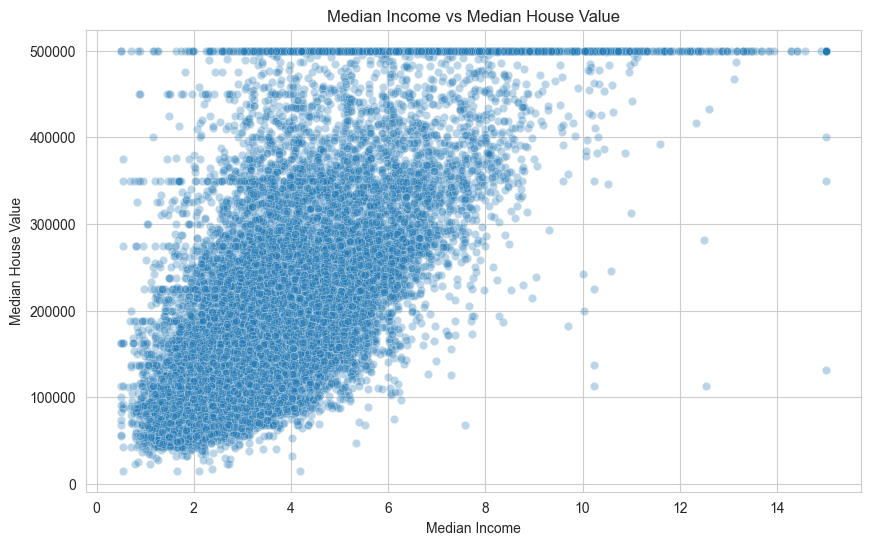

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="median_income",
    y="median_house_value",
    alpha=0.3
)

plt.title("Median Income vs Median House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")

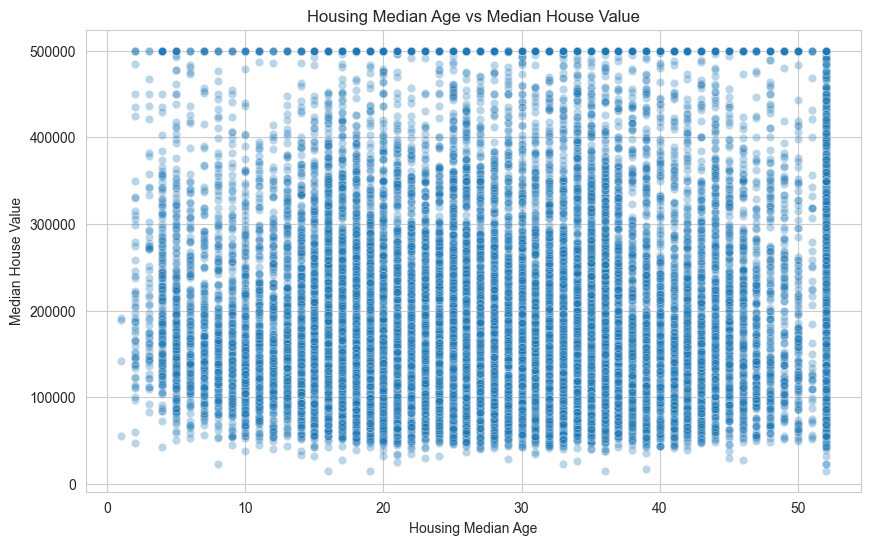

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="housing_median_age",
    y="median_house_value",
    alpha=0.3
)

plt.title("Housing Median Age vs Median House Value")
plt.xlabel("Housing Median Age")
plt.ylabel("Median House Value")

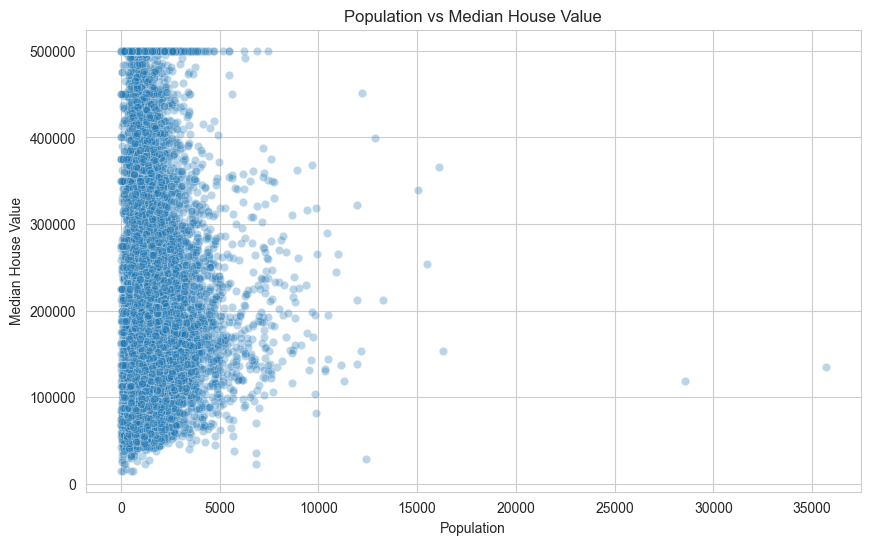

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="population",
    y="median_house_value",
    alpha=0.3
)

plt.title("Population vs Median House Value")
plt.xlabel("Population")
plt.ylabel("Median House Value")

We also look at `median_house_value` broken down by `ocean_proximity`, since it's the one feature not captured by the correlation matrix above.

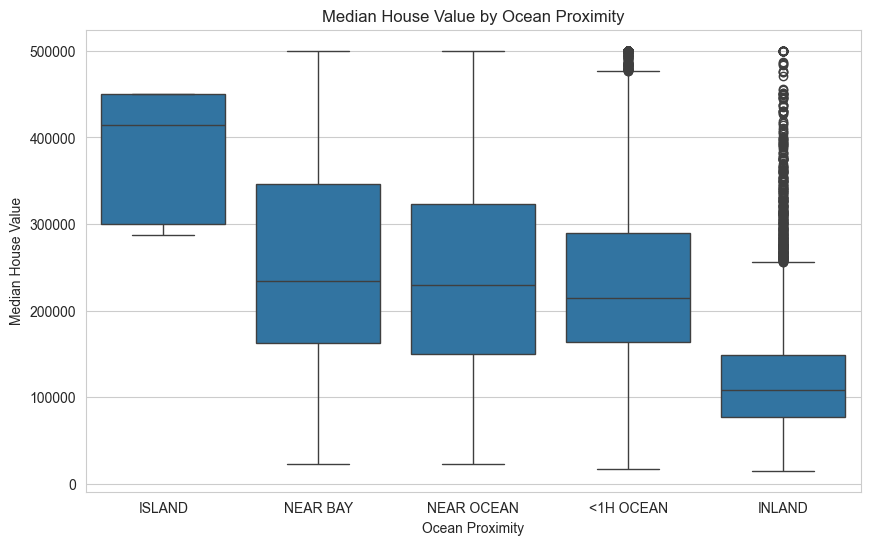

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="ocean_proximity",
    y="median_house_value",
    order=df.groupby("ocean_proximity")["median_house_value"].median().sort_values(ascending=False).index
)

plt.title("Median House Value by Ocean Proximity")
plt.xlabel("Ocean Proximity")
plt.ylabel("Median House Value")

## 14. Feature Engineering Exploration

Raw counts like `total_rooms` and `total_bedrooms` are less meaningful on their own than they are as ratios per household. We construct a few candidate features and check whether they correlate more strongly with the target than the originals.

In [27]:
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]
df["population_per_household"] = df["population"] / df["households"]

engineered_corr = df[[
    "median_house_value",
    "rooms_per_household",
    "bedrooms_per_room",
    "population_per_household"
]].corr()["median_house_value"].sort_values(ascending=False)

engineered_corr

median_house_value          1.000000
rooms_per_household         0.151948
population_per_household   -0.023737
bedrooms_per_room          -0.255880
Name: median_house_value, dtype: float64

These engineered ratios are candidates to carry forward into preprocessing — compare their correlation with the target against the raw `total_rooms`/`total_bedrooms`/`population` figures from Section 12.

## 15. EDA Findings

### Dataset Structure
- The dataset contains multiple numerical features describing housing districts in California, plus one categorical feature (`ocean_proximity`).
- `median_house_value` is used as the target variable.

### Data Quality
- Missing values were identified (concentrated in `total_bedrooms`) and should be handled during preprocessing.
- Duplicate records were checked.
- `median_house_value` is capped at $500,001 — a meaningful share of districts sit exactly at this value, which is a data quality/censoring issue rather than a natural outlier. `housing_median_age` shows a similar capping pattern at its maximum.

### Feature Distributions
- Several numerical features have skewed distributions.
- `ocean_proximity` is unevenly distributed, with a small number of districts in the `ISLAND` category.
- Some features contain potential outliers that should be investigated before modeling.

### Correlation
- `median_income` shows a relatively strong positive relationship with `median_house_value`.
- Other raw numerical features show weaker linear relationships with the target; engineered ratios (`rooms_per_household`, `bedrooms_per_room`, `population_per_household`) correlate more strongly than the raw counts they're derived from.
- Other features show weaker linear relationships with the target.

### Feature vs Target
- The relationship between `median_income` and `median_house_value` appears to be particularly important.
- `ocean_proximity` shows a clear association with price (coastal categories trend higher than `INLAND`).
- Geographic position (`latitude`/`longitude`) reveals clear regional price clusters (e.g. coastal and Bay Area districts), which the correlation matrix alone does not capture.
- Some feature-target relationships do not appear to be strictly linear.

### Modeling Considerations
- Missing values need to be handled before model training.
- The capped target values need an explicit decision (drop, censor-aware modeling, or documented caveat).
- Numerical features may require preprocessing (e.g. scaling, log-transforms for skewed features) depending on the selected model.
- `ocean_proximity` needs categorical encoding (e.g. one-hot).
- Potential outliers should be investigated rather than automatically removed.
- Engineered ratio features are worth carrying into the modeling stage.
- Feature relationships, including geographic structure, should be considered when selecting and evaluating regression models.

## 16. Modeling Considerations

Based on the EDA, the following considerations should be addressed before model training:

1. Handle missing values appropriately (e.g. impute `total_bedrooms`).
2. Decide how to handle the capped `median_house_value` records.
3. Review potential outliers.
4. Encode the `ocean_proximity` categorical feature.
5. Add engineered features (`rooms_per_household`, `bedrooms_per_room`, `population_per_household`).
6. Select relevant features.
7. Apply appropriate preprocessing to numerical features (e.g. scaling, log-transform for skewed distributions).
8. Split the dataset into training and testing sets.
9. Evaluate the regression model using appropriate metrics such as MAE, MSE, and RMSE.